# There's one cavaet, due to some technical issues, new f1 races data can not be feteched. Data from till 2022 have been successfully loaded.

In [2]:
import fastf1
import pandas as pd
import numpy as np

In [3]:
pip install --upgrade fastf1

  Attempting uninstall: fastf1
    Found existing installation: fastf1 3.8.1
    Uninstalling fastf1-3.8.1:
      Successfully uninstalled fastf1-3.8.1
Note: you may need to restart the kernel to use updated packages.


In [3]:
print(fastf1.__version__)

3.9.2


In [3]:
import os

if not os.path.exists('cache'):
    os.makedirs('cache')
fastf1.Cache.enable_cache('cache')

/opt/homebrew/Cellar/jupyterlab/4.5.4/libexec/lib/python3.14/site-packages/fastf1/req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


In [4]:
session = fastf1.get_session(2026, 'Mexico', 'R')
session.load()

req         WARNING 	DEFAULT CACHE ENABLED! (569.47 MB) /Users/hemant/Library/Caches/fastf1
core           INFO 	Loading data for Mexico City Grand Prix - Race [v3.9.2]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
tokens         INFO 	Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
core        WARNI

In [9]:
session.load()

core           INFO 	Loading data for Mexico City Grand Prix - Race [v3.9.2]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
tokens         INFO 	Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
core        WARNING 	Failed to load extended driver information!
req            INFO 	No cached data found fo

In [8]:
ver = session.laps.pick_driver('VER')
ham = session.laps.pick_driver('HAM')

DataNotLoadedError: The data you are trying to access has not been loaded yet. See `Session.load`

In [10]:
ses = fastf1.get_session(2025, 'Singapore', 'R')
ses.load(laps=True, telemetry=False, weather=False, messages=False)
print(len(ses.laps))

core           INFO 	Loading data for Singapore Grand Prix - Race [v3.9.2]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
tokens         INFO 	Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
core        WARNING 	Failed to load extended driver information!
req            INFO 	No cached data found for 

DataNotLoadedError: The data you are trying to access has not been loaded yet. See `Session.load`

In [ ]:
mexico = fastf1.get_session(2022, 'Mexico', 'R')
mexico.load()

core           INFO 	Loading data for Mexico City Grand Prix - Race [v3.9.2]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
tokens         INFO 	Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_stat

In [34]:
ham = mexico.laps.pick_drivers('HAM')
ver = mexico.laps.pick_drivers('VER')
per = mexico.laps.pick_drivers('PER')

In [35]:
ham_fastest_lap = ham.pick_fastest()
ver_fastest_lap = ver.pick_fastest()
per_fastest_lap = per.pick_fastest()

In [36]:
from fastf1 import plotting

In [37]:
ham_tele = ham_fastest_lap.get_telemetry()
ver_tele = ver_fastest_lap.get_telemetry()
per_tele = per_fastest_lap.get_telemetry()

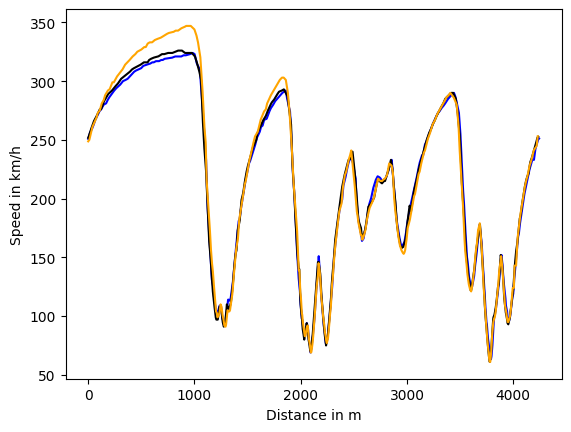

In [39]:
import matplotlib.pyplot as plt

plotting.setup_mpl()

plt.plot(ham_tele['Distance'], ham_tele['Speed'], color="blue")
plt.plot(ver_tele['Distance'], ver_tele['Speed'], color="black")
plt.plot(per_tele['Distance'], per_tele['Speed'], color="orange")
plt.xlabel("Distance in m")
plt.ylabel("Speed in km/h")
plt.show()

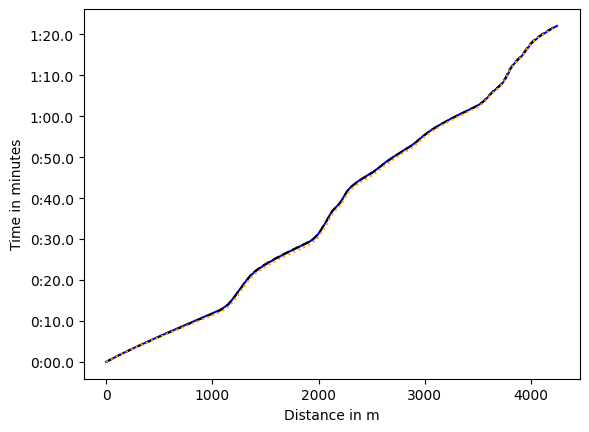

In [46]:
plt.plot(ham_tele['Distance'], ham_tele['Time'], color="blue", linestyle = '-')
plt.plot(ver_tele['Distance'], ver_tele['Time'], color="black", linestyle = '--')
plt.plot(per_tele['Distance'], per_tele['Time'], color="orange", linestyle = ':')
plt.xlabel("Distance in m")
plt.ylabel("Time in minutes")
plt.show()

In [29]:
print("Mexico'22 Race Results: ", mexico.results)

Mexico'22 Race Results:     DriverNumber BroadcastName Abbreviation         DriverId         TeamName  \
1             1  M VERSTAPPEN          VER   max_verstappen  Red Bull Racing   
44           44    L HAMILTON          HAM         hamilton         Mercedes   
11           11       S PEREZ          PER            perez  Red Bull Racing   
63           63     G RUSSELL          RUS          russell         Mercedes   
55           55       C SAINZ          SAI            sainz          Ferrari   
16           16     C LECLERC          LEC          leclerc          Ferrari   
3             3   D RICCIARDO          RIC        ricciardo          McLaren   
31           31        E OCON          OCO             ocon           Alpine   
4             4      L NORRIS          NOR           norris          McLaren   
77           77      V BOTTAS          BOT           bottas       Alfa Romeo   
10           10       P GASLY          GAS            gasly       AlphaTauri   
23           23

In [30]:
print(ham_fastest_lap)

Time                      0 days 01:46:57.064000
Driver                                       HAM
DriverNumber                                  44
LapTime                   0 days 00:01:22.062000
LapNumber                                   32.0
Stint                                        2.0
PitOutTime                                   NaT
PitInTime                                    NaT
Sector1Time               0 days 00:00:29.140000
Sector2Time               0 days 00:00:31.798000
Sector3Time               0 days 00:00:21.124000
Sector1SessionTime        0 days 01:46:04.152000
Sector2SessionTime        0 days 01:46:35.950000
Sector3SessionTime        0 days 01:46:57.074000
SpeedI1                                    284.0
SpeedI2                                    278.0
SpeedFL                                    245.0
SpeedST                                    323.0
IsPersonalBest                              True
Compound                                    HARD
TyreLife            

In [31]:
print(ver_fastest_lap)

Time                      0 days 01:52:19.105000
Driver                                       VER
DriverNumber                                   1
LapTime                   0 days 00:01:22.046000
LapNumber                                   36.0
Stint                                        2.0
PitOutTime                                   NaT
PitInTime                                    NaT
Sector1Time               0 days 00:00:29.174000
Sector2Time               0 days 00:00:31.718000
Sector3Time               0 days 00:00:21.154000
Sector1SessionTime        0 days 01:51:26.248000
Sector2SessionTime        0 days 01:51:57.966000
Sector3SessionTime        0 days 01:52:19.120000
SpeedI1                                    288.0
SpeedI2                                    281.0
SpeedFL                                    245.0
SpeedST                                    325.0
IsPersonalBest                              True
Compound                                  MEDIUM
TyreLife            

NameError: name 'ham' is not defined